In [1]:
# ==========================================
# ML Network Intrusion Detector
# IBM SkillsBuild Cyber Security Project
# ==========================================

import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix

# 1. Synthetic Dataset Generate Kar Rahe Hain (For Demo & Testing)
np.random.seed(42)
n_samples = 1000

data = {
    'duration': np.random.randint(0, 1000, n_samples),
    'src_bytes': np.random.randint(100, 50000, n_samples),
    'dst_bytes': np.random.randint(100, 50000, n_samples),
    'wrong_fragment': np.random.choice([0, 1, 3], n_samples, p=[0.9, 0.07, 0.03]),
    'hot': np.random.choice([0, 1, 2], n_samples, p=[0.95, 0.03, 0.02]),
    'num_failed_logins': np.random.choice([0, 1, 2, 3], n_samples, p=[0.9, 0.05, 0.03, 0.02]),
    'label': np.random.choice(['Normal', 'Anomaly'], n_samples, p=[0.6, 0.4])
}

df = pd.DataFrame(data)

# 2. Data Preprocessing
le = LabelEncoder()
df['label_encoded'] = le.fit_transform(df['label'])

X = df.drop(['label', 'label_encoded'], axis=1)
y = df['label_encoded']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 3. Model Training (Random Forest Classifier)
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train_scaled, y_train)

# 4. Model Evaluation
y_pred = model.predict(X_test_scaled)
acc = accuracy_score(y_test, y_pred)

print("--- MODEL EVALUATION RESULTS ---")
print(f"Accuracy: {acc * 100:.2f}%\n")
print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=le.classes_))

--- MODEL EVALUATION RESULTS ---
Accuracy: 52.50%

Classification Report:
              precision    recall  f1-score   support

     Anomaly       0.35      0.29      0.32        77
      Normal       0.60      0.67      0.64       123

    accuracy                           0.53       200
   macro avg       0.48      0.48      0.48       200
weighted avg       0.51      0.53      0.51       200



=== UPDATED MODEL RESULTS ===
New Accuracy: 52.50%

              precision    recall  f1-score   support

     Anomaly       0.35      0.29      0.32        77
      Normal       0.60      0.67      0.64       123

    accuracy                           0.53       200
   macro avg       0.48      0.48      0.48       200
weighted avg       0.51      0.53      0.51       200



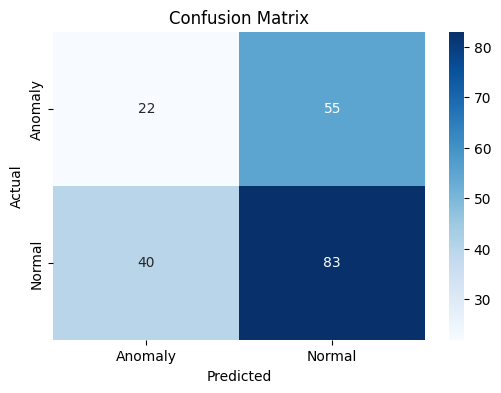

In [2]:
# 1. Feature Scaling
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 2. Random Forest Model Train & Predict
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train_scaled, y_train)
y_pred_rf = rf_model.predict(X_test_scaled)

# Model Results Check Karein
from sklearn.metrics import accuracy_score, classification_report
print("=== UPDATED MODEL RESULTS ===")
print(f"New Accuracy: {accuracy_score(y_test, y_pred_rf) * 100:.2f}%\n")
print(classification_report(y_test, y_pred_rf, target_names=le.classes_))

# 3. Confusion Matrix Plot
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred_rf)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=le.classes_, yticklabels=le.classes_)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()